<a href="https://colab.research.google.com/github/kunjana30/Internship-Project-2/blob/main/Task3_Country_Wise_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 3 (Medium) – Country-Wise Netflix Content Analysis

**Goal:** Analyse how Netflix content is distributed across countries, and which countries produce the most.

**Prerequisite:** run the Task 1 notebook first (it creates `netflix_cleaned.csv`).

| Step | What we do |
|------|-----------|
| 1 | Extract and clean country information |
| 2 | Calculate content count by country (GroupBy) |
| 3 | Identify top content-producing countries |
| 4 | Create charts and rankings |
| 5 | Generate business insights |

### ☁️ Google Colab / Drive setup – run this cell first
Colab's storage is **temporary**: files in `/content` disappear when the session ends, and each notebook runs in its own session.
So this cell connects to your **Google Drive** and works inside a folder called `Netflix_Analysis`, keeping `Dataset.csv`,
`netflix_cleaned.csv` (created by Task 1) and all outputs in one permanent place.

* A pop-up will ask you to allow Drive access - choose your account and click **Allow**.
* Make sure `MyDrive/Netflix_Analysis/` contains `Dataset.csv` (and `netflix_cleaned.csv` once Task 1 has been run).
* **Running locally in Jupyter?** This cell does nothing outside Colab, so you can leave it as it is.
* **No Drive?** Set `USE_DRIVE = False` and upload the files with the Files panel (folder icon on the left). They are deleted when the runtime resets.

In [ ]:
import os, sys

USE_DRIVE = True                                          # set to False to skip Google Drive
PROJECT_DIR = "/content/drive/MyDrive/Netflix_Analysis"   # the folder in your Drive that holds the project files

if "google.colab" in sys.modules and USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    os.makedirs(PROJECT_DIR, exist_ok=True)
    os.chdir(PROJECT_DIR)

print("Working folder:", os.getcwd())
print("Files here    :", sorted(os.listdir(".")))

Mounted at /content/drive
Working folder: /content/drive/MyDrive/Netflix_Analysis
Files here    : ['Dataset.csv', 'Task1_Data_Cleaning_Preparation.ipynb', 'Task2_Content_Type_Analysis.ipynb', 'Task3_Country_Wise_Analysis.ipynb', 'Task4_Trend_Analysis_Release_Year.ipynb', 'Task5_Content_Rating_Genre_Analysis.ipynb', 'Task6_Business_Insights_Report.ipynb', 'netflix_cleaned.csv', 'outputs']


---
## Step 1 – Extract and clean country information

In [ ]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook", rc={"axes.grid.axis": "y"})
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 13,
                     "axes.spines.top": False, "axes.spines.right": False})

# Netflix-inspired colours used consistently across every chart
NETFLIX_RED, NETFLIX_DARK, GREY = "#E50914", "#221F1F", "#B3B3B3"
TYPE_COLORS = {"Movie": NETFLIX_RED, "TV Show": NETFLIX_DARK}

CLEAN_PATH = Path("netflix_cleaned.csv")          # created by Task 1
OUT_DIR = Path("outputs/task3_country_analysis")                   # charts & tables are saved here (for your screenshots/report)
OUT_DIR.mkdir(parents=True, exist_ok=True)

def save_fig(name):
    """Save the current matplotlib figure into the task's output folder."""
    plt.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

if not CLEAN_PATH.exists():
    raise FileNotFoundError("'netflix_cleaned.csv' not found. Run the Task 1 notebook first and keep this notebook in the same folder.")

In [ ]:
df = pd.read_csv(CLEAN_PATH, parse_dates=["date_added"])
print(f"Loaded {len(df):,} titles x {df.shape[1]} columns")
df.head()

Loaded 8,786 titles x 18 columns


,show_id,type,title,director,country,date_added,year_added,month_added,month_name,release_year,rating,rating_group,duration,duration_min,seasons,listed_in,n_genres,primary_genre
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2021,9,September,2020,PG-13,Teens,90 min,90.0,NaN,Documentaries,1,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,9,September,2021,TV-MA,Adults,1 Season,NaN,1.0,"Crime TV Shows, International TV Shows, TV Act...",3,Crime TV Shows
2,s11,TV Show,"Vendetta: Truth, Lies and The Mafia",Unknown,Pakistan,2021-09-24,2021,9,September,2021,TV-MA,Adults,1 Season,NaN,1.0,"Crime TV Shows, Docuseries, International TV S...",3,Crime TV Shows
3,s7,Movie,My Little Pony: A New Generation,"Robert Cullen, José Luis Ucha",Unknown,2021-09-24,2021,9,September,2021,PG,Older Kids,91 min,91.0,NaN,Children & Family Movies,1,Children & Family Movies
4,s5,TV Show,Kota Factory,Unknown,India,2021-09-24,2021,9,September,2021,TV-MA,Adults,2 Seasons,NaN,2.0,"International TV Shows, Romantic TV Shows, TV ...",3,International TV Shows


### 1a. Handle multi-country titles safely
Many Netflix datasets list several countries in one cell (`"United States, India"`). The safe pattern is **split → explode → strip**,
which turns one row into one row *per country*. In this file every title has a single country, so the explode changes nothing – but we verify that instead of assuming it.

In [ ]:
print("Distinct country values  :", df["country"].nunique())
unknown_n = int((df["country"] == "Unknown").sum())
print(f"Titles with unknown country: {unknown_n:,} ({unknown_n / len(df):.1%})")

country_long = (
    df.assign(country=df["country"].str.split(","))
      .explode("country")
      .reset_index(drop=True)          # explode repeats index labels - always reset them
)
country_long["country"] = country_long["country"].str.strip()

same = len(country_long) == len(df)
print(f"\nRows before explode: {len(df):,} | after: {len(country_long):,} ->",
      "no multi-country titles in this file" if same else "multi-country titles were split into separate rows")

# Rankings should only use titles whose country is actually known
known = country_long[country_long["country"] != "Unknown"].copy()
print(f"Titles with a known country: {len(known):,} ({len(known) / len(df):.1%} of the catalogue)")

Distinct country values  : 85
Titles with unknown country: 287 (3.3%)

Rows before explode: 8,786 | after: 8,786 -> no multi-country titles in this file
Titles with a known country: 8,499 (96.7% of the catalogue)


### 1b. Add a continent / region column
Country-level counts are fine-grained; grouping into regions gives the **geographic insight** the task asks for.
Transcontinental countries are a judgement call (Turkey and Georgia → Asia; Russia and Cyprus → Europe).

In [ ]:
REGION = {
    # North America (incl. Central America & Caribbean)
    "United States": "North America", "Canada": "North America", "Mexico": "North America",
    "Guatemala": "North America", "Jamaica": "North America", "Puerto Rico": "North America",
    # South America
    "Argentina": "South America", "Brazil": "South America", "Chile": "South America", "Colombia": "South America",
    "Paraguay": "South America", "Peru": "South America", "Uruguay": "South America", "Venezuela": "South America",
    # Europe
    "United Kingdom": "Europe", "France": "Europe", "Germany": "Europe", "Spain": "Europe", "Italy": "Europe",
    "Netherlands": "Europe", "Belgium": "Europe", "Sweden": "Europe", "Norway": "Europe", "Denmark": "Europe",
    "Finland": "Europe", "Iceland": "Europe", "Ireland": "Europe", "Switzerland": "Europe", "Austria": "Europe",
    "Poland": "Europe", "Portugal": "Europe", "Greece": "Europe", "Hungary": "Europe", "Czech Republic": "Europe",
    "Romania": "Europe", "Bulgaria": "Europe", "Croatia": "Europe", "Serbia": "Europe", "Slovenia": "Europe",
    "Luxembourg": "Europe", "Ukraine": "Europe", "Belarus": "Europe", "Russia": "Europe", "Cyprus": "Europe",
    "Soviet Union": "Europe",
    # Asia (incl. Middle East)
    "India": "Asia", "Pakistan": "Asia", "Bangladesh": "Asia", "Japan": "Asia", "South Korea": "Asia", "China": "Asia",
    "Hong Kong": "Asia", "Taiwan": "Asia", "Thailand": "Asia", "Indonesia": "Asia", "Philippines": "Asia",
    "Malaysia": "Asia", "Singapore": "Asia", "Vietnam": "Asia", "Cambodia": "Asia", "Turkey": "Asia", "Georgia": "Asia",
    "Israel": "Asia", "Iran": "Asia", "Syria": "Asia", "Lebanon": "Asia", "Jordan": "Asia", "Kuwait": "Asia",
    "Saudi Arabia": "Asia", "United Arab Emirates": "Asia",
    # Africa
    "Egypt": "Africa", "Nigeria": "Africa", "South Africa": "Africa", "Kenya": "Africa", "Ghana": "Africa",
    "Cameroon": "Africa", "Mauritius": "Africa", "Mozambique": "Africa", "Namibia": "Africa", "Senegal": "Africa",
    "Somalia": "Africa", "Zimbabwe": "Africa",
    # Oceania
    "Australia": "Oceania", "New Zealand": "Oceania",
}

known["region"] = known["country"].map(REGION)
unmapped = sorted(known.loc[known["region"].isna(), "country"].unique())
assert not unmapped, f"Add these countries to REGION: {unmapped}"
print("Every country mapped to a region ✔")
known["region"].value_counts()

Every country mapped to a region ✔


,count
region,
North America,3652
Asia,2716
Europe,1468
Africa,286
South America,246
Oceania,131


---
## Step 2 – Calculate content count by country
`groupby` splits the data into one group per country, then we count the titles in each group.
We add **share %** and **cumulative %**, and split every country's count into Movies vs TV Shows.

In [ ]:
country_counts = (
    known.groupby("country").size()
         .sort_values(ascending=False)
         .rename("titles").reset_index()
)
country_counts["share_%"] = (country_counts["titles"] / country_counts["titles"].sum() * 100).round(2)
country_counts["cumulative_%"] = country_counts["share_%"].cumsum().round(1)

by_type = pd.crosstab(known["country"], known["type"])            # Movies vs TV Shows per country
country_table = country_counts.merge(by_type, left_on="country", right_index=True)
country_table["tv_share_%"] = (country_table["TV Show"] / country_table["titles"] * 100).round(1)
country_table.insert(0, "rank", range(1, len(country_table) + 1))

print(f"{len(country_table)} countries with at least one title")
country_table.head(15)

84 countries with at least one title


,rank,country,titles,share_%,cumulative_%,Movie,TV Show,tv_share_%
0,1,United States,3240,38.12,38.1,2395,845,26.1
1,2,India,1056,12.42,50.5,975,81,7.7
2,3,United Kingdom,638,7.51,58.0,387,251,39.3
3,4,Pakistan,420,4.94,63.0,71,349,83.1
4,5,Canada,271,3.19,66.2,187,84,31.0
5,6,Japan,259,3.05,69.2,87,172,66.4
6,7,South Korea,214,2.52,71.7,49,165,77.1
7,8,France,213,2.51,74.3,148,65,30.5
8,9,Spain,182,2.14,76.4,129,53,29.1
9,10,Mexico,138,1.62,78.0,90,48,34.8


---
## Step 3 – Identify top content-producing countries

In [ ]:
TOP_N = 10
top = country_table.head(TOP_N)
print(f"Top {TOP_N} countries")
print(top[["rank", "country", "titles", "share_%", "Movie", "TV Show"]].to_string(index=False))

# How concentrated is the catalogue?
for k in (1, 3, 5, 10):
    print(f"Top {k:>2} countries = {country_table['share_%'].head(k).sum():5.1f}% of titles with a known country")

tail = (country_table["titles"] <= 5).sum()
print(f"\nLong tail: {tail} of {len(country_table)} countries have 5 titles or fewer")

region_table = (known.groupby("region").size().sort_values(ascending=False).rename("titles").reset_index())
region_table["share_%"] = (region_table["titles"] / region_table["titles"].sum() * 100).round(1)
region_table

Top 10 countries
 rank        country  titles  share_%  Movie  TV Show
    1  United States    3240    38.12   2395      845
    2          India    1056    12.42    975       81
    3 United Kingdom     638     7.51    387      251
    4       Pakistan     420     4.94     71      349
    5         Canada     271     3.19    187       84
    6          Japan     259     3.05     87      172
    7    South Korea     214     2.52     49      165
    8         France     213     2.51    148       65
    9          Spain     182     2.14    129       53
   10         Mexico     138     1.62     90       48
Top  1 countries =  38.1% of titles with a known country
Top  3 countries =  58.0% of titles with a known country
Top  5 countries =  66.2% of titles with a known country
Top 10 countries =  78.0% of titles with a known country

Long tail: 32 of 84 countries have 5 titles or fewer


,region,titles,share_%
0,North America,3652,43.0
1,Asia,2716,32.0
2,Europe,1468,17.3
3,Africa,286,3.4
4,South America,246,2.9
5,Oceania,131,1.5


---
## Step 4 – Create charts and rankings
### 4a. Top 15 countries – the ranking chart

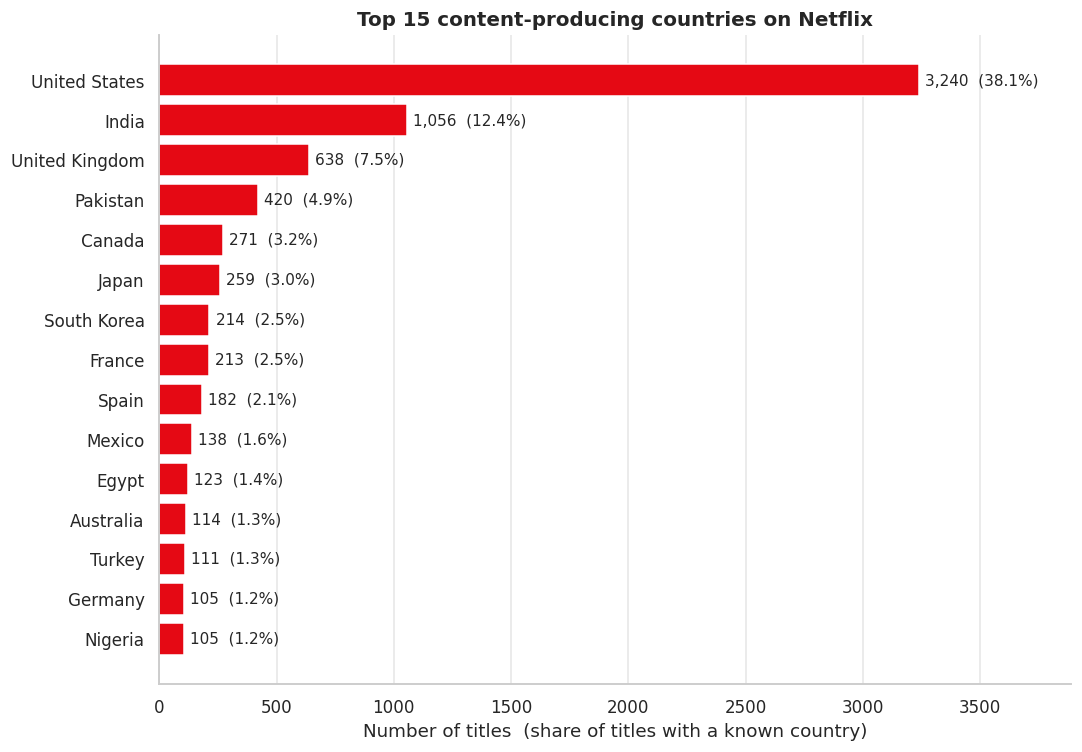

In [ ]:
top15 = country_table.head(15).iloc[::-1]                 # reversed so rank 1 is at the top of a horizontal bar chart

fig, ax = plt.subplots(figsize=(10, 7))
bars = ax.barh(top15["country"], top15["titles"], color=NETFLIX_RED)
ax.bar_label(bars, labels=[f"{t:,}  ({s:.1f}%)" for t, s in zip(top15["titles"], top15["share_%"])], padding=4, fontsize=10)
ax.set_xlim(0, top15["titles"].max() * 1.2)
ax.set_title("Top 15 content-producing countries on Netflix")
ax.set_xlabel("Number of titles  (share of titles with a known country)")
ax.grid(axis="x", alpha=0.5); ax.grid(axis="y", visible=False)
plt.tight_layout(); save_fig("01_top15_countries"); plt.show()

### 4b. Movies vs TV Shows by country
Left: how each top-10 country's output splits. Right: which countries (with at least 50 titles) are **TV-led** vs **movie-led**.

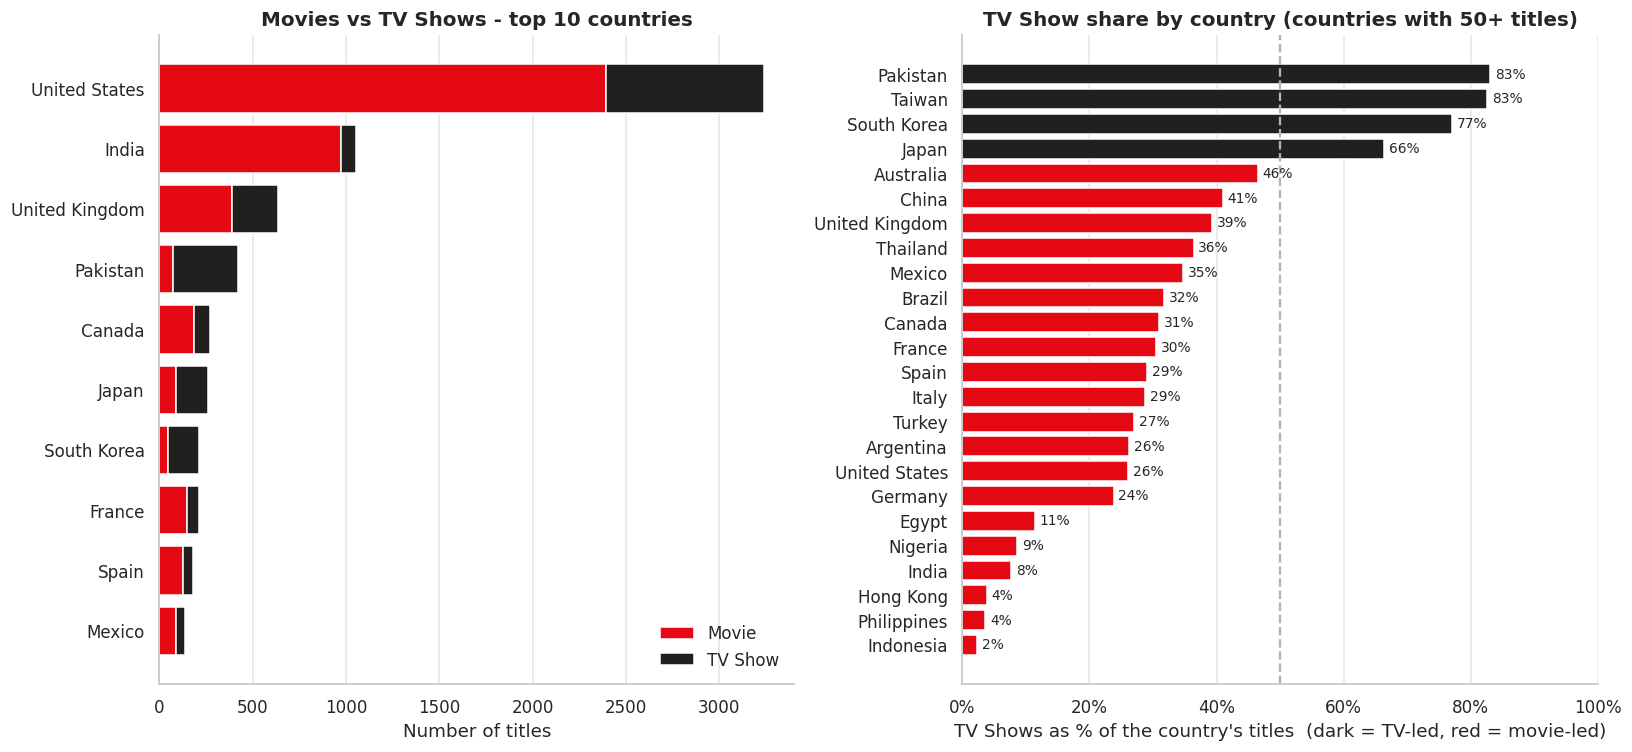

In [ ]:
t10 = country_table.head(10).iloc[::-1]
big = country_table[country_table["titles"] >= 50].sort_values("tv_share_%")

fig, axes = plt.subplots(1, 2, figsize=(15, 7))

axes[0].barh(t10["country"], t10["Movie"], color=NETFLIX_RED, label="Movie")
axes[0].barh(t10["country"], t10["TV Show"], left=t10["Movie"], color=NETFLIX_DARK, label="TV Show")
axes[0].set_title("Movies vs TV Shows - top 10 countries"); axes[0].set_xlabel("Number of titles")
axes[0].legend(frameon=False, loc="lower right"); axes[0].grid(axis="x", alpha=0.5); axes[0].grid(axis="y", visible=False)

bar_colors = [NETFLIX_DARK if v >= 50 else NETFLIX_RED for v in big["tv_share_%"]]
bars = axes[1].barh(big["country"], big["tv_share_%"], color=bar_colors)
axes[1].bar_label(bars, fmt="%.0f%%", padding=3, fontsize=9)
axes[1].axvline(50, color=GREY, linestyle="--")
axes[1].set_xlim(0, 100); axes[1].xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
axes[1].set_title("TV Show share by country (countries with 50+ titles)")
axes[1].set_xlabel("TV Shows as % of the country's titles  (dark = TV-led, red = movie-led)")
axes[1].grid(axis="x", alpha=0.5); axes[1].grid(axis="y", visible=False)

plt.tight_layout(); save_fig("02_movies_vs_tv_by_country"); plt.show()

### 4c. How concentrated is the catalogue? (Pareto chart) and regional view

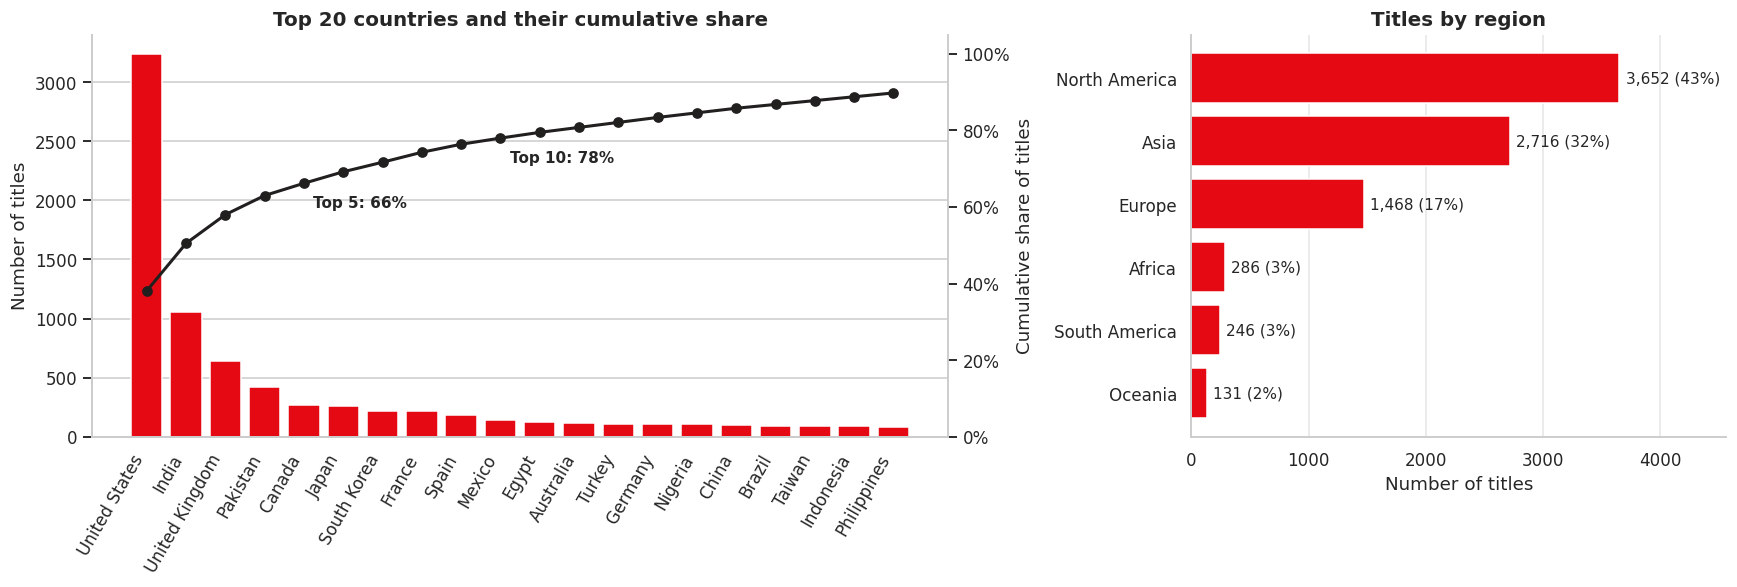

In [ ]:
top20 = country_table.head(20)
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={"width_ratios": [1.6, 1]})

# Pareto: bars = titles, line = cumulative share
axes[0].bar(top20["country"], top20["titles"], color=NETFLIX_RED)
axes[0].set_ylabel("Number of titles"); axes[0].tick_params(axis="x", rotation=60)
for lbl in axes[0].get_xticklabels(): lbl.set_ha("right")
ax2 = axes[0].twinx()
ax2.plot(top20["country"], top20["cumulative_%"], color=NETFLIX_DARK, marker="o", linewidth=2)
ax2.set_ylim(0, 105); ax2.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0)); ax2.grid(False)
ax2.spines["right"].set_visible(True); ax2.set_ylabel("Cumulative share of titles")
for k in (4, 9):                                         # label the Top-5 and Top-10 points
    ax2.annotate(f"Top {k + 1}: {top20['cumulative_%'].iloc[k]:.0f}%", (k, top20["cumulative_%"].iloc[k]),
                 textcoords="offset points", xytext=(6, -16), fontsize=10, fontweight="bold")
axes[0].set_title("Top 20 countries and their cumulative share")

# Regions
r = region_table.iloc[::-1]
bars = axes[1].barh(r["region"], r["titles"], color=NETFLIX_RED)
axes[1].bar_label(bars, labels=[f"{t:,} ({s:.0f}%)" for t, s in zip(r["titles"], r["share_%"])], padding=4, fontsize=10)
axes[1].set_xlim(0, r["titles"].max() * 1.25)
axes[1].set_title("Titles by region"); axes[1].set_xlabel("Number of titles")
axes[1].grid(axis="x", alpha=0.5); axes[1].grid(axis="y", visible=False)

plt.tight_layout(); save_fig("03_concentration_and_regions"); plt.show()

### 4d. Who is each country's content aimed at?
Heatmap of the audience group (from the `rating_group` we built in Task 1) for each top-10 country. Each **row adds up to 100%**.

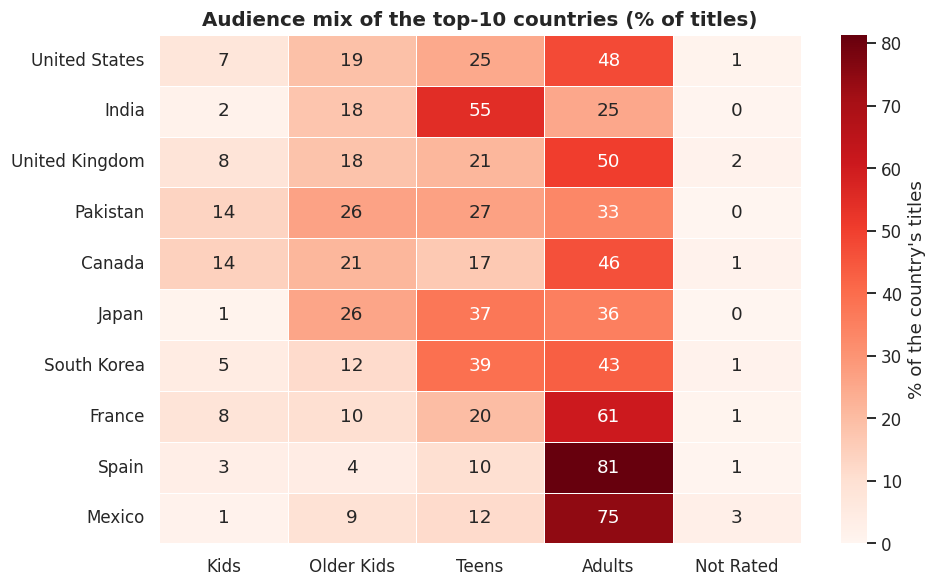

In [ ]:
group_order = ["Kids", "Older Kids", "Teens", "Adults", "Not Rated"]
top10_names = country_table.head(10)["country"].tolist()

heat = (pd.crosstab(known["country"], known["rating_group"], normalize="index") * 100)
heat = heat.loc[top10_names, group_order]

plt.figure(figsize=(9, 5.5))
sns.heatmap(heat, annot=True, fmt=".0f", cmap="Reds", linewidths=0.5, cbar_kws={"label": "% of the country's titles"})
plt.title("Audience mix of the top-10 countries (% of titles)")
plt.xlabel(""); plt.ylabel("")
plt.tight_layout(); save_fig("04_country_audience_heatmap"); plt.show()

In [ ]:
# Save the full ranking for your report
country_table.to_csv(OUT_DIR / "country_ranking.csv", index=False)
region_table.to_csv(OUT_DIR / "region_summary.csv", index=False)
print("Saved country_ranking.csv and region_summary.csv in", OUT_DIR)

Saved country_ranking.csv and region_summary.csv in outputs/task3_country_analysis


---
## Step 5 – Generate business insights
Numbers in the bullets are generated from the data, so they always match the tables and charts above.

In [ ]:
n_known = len(known)
us_share = country_table.loc[country_table["country"] == "United States", "share_%"].iloc[0]
top5_share = country_table["share_%"].head(5).sum()
non_us = 100 - us_share

tv_led = big.sort_values("tv_share_%", ascending=False).head(4)
movie_led = big.sort_values("tv_share_%").head(4)
tv_names = lambda d: ", ".join(f"{c} ({v:.0f}% TV)" for c, v in zip(d["country"], d["tv_share_%"]))
movie_names = lambda d: ", ".join(f"{c} ({100 - v:.0f}% movies)" for c, v in zip(d["country"], d["tv_share_%"]))

asia_share = region_table.loc[region_table["region"] == "Asia", "share_%"].iloc[0]
europe_share = region_table.loc[region_table["region"] == "Europe", "share_%"].iloc[0]
africa_sa = region_table.set_index("region").loc[["Africa", "South America"], "share_%"].sum()

adult_top = heat["Adults"].idxmax(); kids_top = (heat["Kids"] + heat["Older Kids"]).idxmax()

insights = [
    f"**The US is the single biggest source, but not the majority.** The US accounts for {us_share:.1f}% of titles with a known country, so {non_us:.0f}% of the catalogue is international.",
    f"**Content is concentrated.** Just five countries make up {top5_share:.0f}% of the catalogue, and {tail} of {len(country_table)} countries have 5 titles or fewer.",
    f"**Asia is a major pillar.** Asia supplies {asia_share:.0f}% of titles (India alone is #2), ahead of Europe at {europe_share:.0f}%.",
    f"**Different countries = different formats.** TV-led: {tv_names(tv_led)}. Movie-led: {movie_names(movie_led)}.",
    f"**Audience mix varies by country.** {adult_top} has the highest share of Adult-rated content among the top 10, while {kids_top} has the most content for Kids/Older Kids.",
    f"**Under-represented regions.** Africa and South America combined are only {africa_sa:.0f}% of titles - a gap (and potential growth area) for local-language content.",
]
display(Markdown("\n\n".join(f"{i}. {t}" for i, t in enumerate(insights, 1))))

1. **The US is the single biggest source, but not the majority.** The US accounts for 38.1% of titles with a known country, so 62% of the catalogue is international.

2. **Content is concentrated.** Just five countries make up 66% of the catalogue, and 32 of 84 countries have 5 titles or fewer.

3. **Asia is a major pillar.** Asia supplies 32% of titles (India alone is #2), ahead of Europe at 17%.

4. **Different countries = different formats.** TV-led: Pakistan (83% TV), Taiwan (83% TV), South Korea (77% TV), Japan (66% TV). Movie-led: Indonesia (98% movies), Philippines (96% movies), Hong Kong (96% movies), India (92% movies).

5. **Audience mix varies by country.** Spain has the highest share of Adult-rated content among the top 10, while Pakistan has the most content for Kids/Older Kids.

6. **Under-represented regions.** Africa and South America combined are only 6% of titles - a gap (and potential growth area) for local-language content.

### Business recommendations (draft – refine in your own words)
* **Keep investing in the US + India + UK core**, which supply most of the catalogue, but track dependence on a handful of markets.
* **TV-led markets (e.g. South Korea, Japan, Taiwan, Pakistan)** are natural sources of binge-worthy series; **movie-led markets (e.g. India, Indonesia, Philippines)** may offer scope to develop more series.
* **Fill regional gaps** (Africa, South America) with local-language originals to grow subscribers in those regions.

> ⚠️ **Caveat:** the data counts *titles*, not viewership, and `country` is the production country, not where a title is *available*.

---
## ✅ Summary
Cleaned and exploded country data, counted content with `groupby`, ranked the top producers, built five visuals (ranking, movie-vs-TV split, Pareto, regional view, audience heatmap) and derived business insights.
Outputs are saved in `outputs/task3_country_analysis/`.